# Midwest rent model

Listings are from 2018 and 2019, so every dollar figure here is a historical asking rent. The scope is the Midwest (about 12,000 usable listings) because the Chicago metro alone has only about 700. All training logic lives in `src/model.py`; this notebook runs it and shows the results.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import model

pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

## Data and engineered features

Price per square foot and cost per bedroom are engineered here for description and for the match score, but they are computed from rent, so they are not used as predictors.

In [2]:
frame = model.load_midwest()
print(f'{len(frame):,} usable Midwest listings, {int(frame.flagged.sum()):,} flagged, {int(frame.is_chicago_metro.sum()):,} in the Chicago metro')
frame[['price', 'square_feet', 'price_per_sqft', 'cost_per_bedroom', 'distance_from_campus_miles', 'amenity_count']].describe().T

12,166 usable Midwest listings, 468 flagged, 730 in the Chicago metro


,count,mean,std,min,25%,50%,75%,max
price,"12,166.000","1,111.608",544.782,224.000,770.000,975.000,"1,316.500","15,000.000"
square_feet,"12,166.000",946.020,393.954,200.000,711.000,888.000,"1,102.750","12,000.000"
price_per_sqft,"12,166.000",1.234,0.539,0.047,0.898,1.086,1.409,9.398
cost_per_bedroom,"12,166.000",705.232,383.737,133.333,436.500,612.500,860.000,"4,000.000"
distance_from_campus_miles,"12,166.000",307.307,150.763,0.723,246.776,294.047,388.446,890.966
amenity_count,"9,882.000",4.007,2.739,1.000,2.000,3.000,5.000,17.000


## Skew

A log transform is applied wherever it brings skewness closer to zero.

In [3]:
skew = model.skew_report(frame)
pd.DataFrame(skew).T

,raw_skew,log_skew,use_log,transform
price,3.761,0.559,True,log
square_feet,5.285,0.229,True,log
distance_from_campus_miles,0.678,-2.225,False,log1p


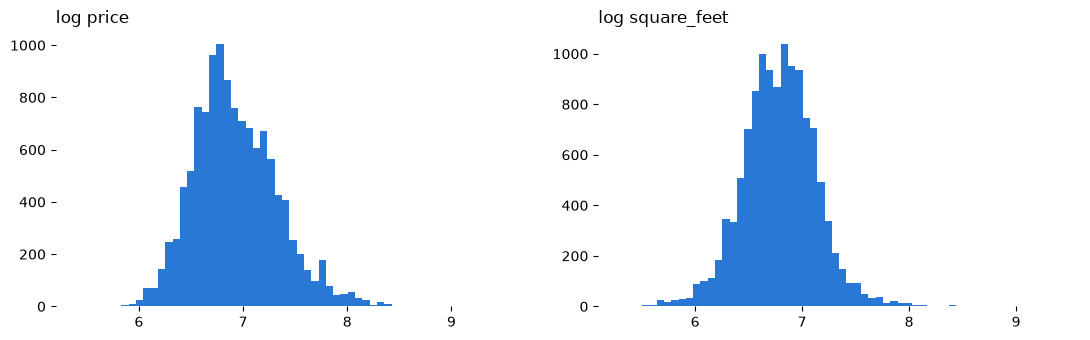

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for axis, column in zip(axes, ['price', 'square_feet']):
    axis.hist(np.log(frame[column]), bins=60, color='#2a78d6')
    axis.set_title(f'log {column}', loc='left')
    for spine in axis.spines.values():
        spine.set_visible(False)
plt.tight_layout()

## Fit both models, with and without flagged rows

`train_all` splits 20% of rows off as a held-out set, stratified on the Chicago metro indicator, runs 5-fold cross validation on the training set, and fits multiple linear regression and a random forest twice: once excluding flagged rows and once including them.

In [5]:
results = model.train_all(write=False)
variants = results['variants']

In [6]:
rows = []
for key, variant in variants.items():
    for subset in ['held_out_all', 'chicago_metro', 'outside_chicago_metro', 'near_campus']:
        rows.append({'variant': key, 'subset': subset, 'model': 'Baseline (mean rent)', **variant['baseline'][subset]})
        for kind in model.MODEL_KINDS:
            rows.append({'variant': key, 'subset': subset, 'model': model.MODEL_NAMES[kind], **variant['models'][kind]['evaluation'][subset]})
comparison = pd.DataFrame(rows)
comparison.pivot_table(index=['variant', 'subset', 'model'], values=['rmse', 'mae', 'r2', 'rows'], sort=False)

rmse  \
variant           subset                model                                  
excluding_flagged held_out_all          Baseline (mean rent)         537.091   
                                        Multiple linear regression   391.431   
                                        Random forest                301.239   
                  chicago_metro         Baseline (mean rent)         968.809   
                                        Multiple linear regression   702.887   
                                        Random forest                506.814   
                  outside_chicago_metro Baseline (mean rent)         500.067   
                                        Multiple linear regression   364.811   
                                        Random forest                284.488   
                  near_campus           Baseline (mean rent)       1,025.849   
                                        Multiple linear regression   718.206   
                                        Random forest                527.159   
including_flagged held_out_all          Baseline (mean rent)         536.505   
                                        Multiple linear regression   388.568   
                                        Random forest                304.296   
                  chicago_metro         Baseline (mean rent)         926.889   
                                        Multiple linear regression   668.560   
                                        Random forest                498.516   
                  outside_chicago_metro Baseline (mean rent)         501.382   
                                        Multiple linear regression   363.452   
                                        Random forest                287.483   
                  near_campus           Baseline (mean rent)         978.406   
                                        Multiple linear regression   682.378   
                                        Random forest                518.059   

                                                                       mae  \
variant           subset                model                                
excluding_flagged held_out_all          Baseline (mean rent)       378.999   
                                        Multiple linear regression 254.434   
                                        Random forest              172.634   
                  chicago_metro         Baseline (mean rent)       668.069   
                                        Multiple linear regression 517.786   
                                        Random forest              322.773   
                  outside_chicago_metro Baseline (mean rent)       361.925   
                                        Multiple linear regression 238.879   
                                        Random forest              163.767   
                  near_campus           Baseline (mean rent)       707.895   
                                        Multiple linear regression 515.466   
                                        Random forest              336.106   
including_flagged held_out_all          Baseline (mean rent)       377.517   
                                        Multiple linear regression 254.634   
                                        Random forest              173.286   
                  chicago_metro         Baseline (mean rent)       635.015   
                                        Multiple linear regression 487.308   
                                        Random forest              321.590   
                  outside_chicago_metro Baseline (mean rent)       361.086   
                                        Multiple linear regression 239.787   
                                        Random forest              163.823   
                  near_campus           Baseline (mean rent)       670.653   
                                        Multiple linear regression 486.088   
                                        R

## Cross validation on the training set

In [7]:
pd.DataFrame([
    {'variant': key, 'model': model.MODEL_NAMES[kind], **{f'{metric}_{stat}': variant['models'][kind]['cross_validation'][metric][stat] for metric in ('rmse', 'mae', 'r2') for stat in ('mean', 'std')}}
    for key, variant in variants.items() for kind in model.MODEL_KINDS
])

,variant,model,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std
0,excluding_flagged,Multiple linear regression,383.698,26.364,248.149,9.427,0.508,0.035
1,excluding_flagged,Random forest,307.873,40.865,169.871,5.335,0.686,0.035
2,including_flagged,Multiple linear regression,385.896,23.448,250.110,3.981,0.497,0.030
3,including_flagged,Random forest,306.449,42.383,169.326,4.837,0.686,0.039


## Residuals: does error grow with price?

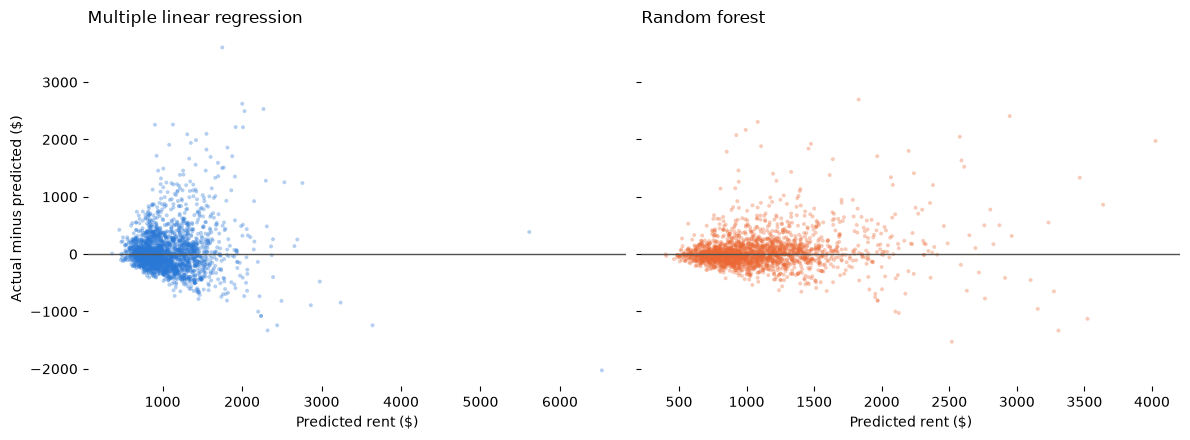

In [8]:
chosen = variants['excluding_flagged']
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for axis, kind in zip(axes, model.MODEL_KINDS):
    plot = chosen['models'][kind]['plot']
    axis.scatter(plot['predicted'], plot['actual'] - plot['predicted'], s=8, alpha=0.35, color=model.SERIES_COLORS[kind], edgecolors='none')
    axis.axhline(0, color='#52514e', linewidth=1)
    axis.set_title(model.MODEL_NAMES[kind], loc='left')
    axis.set_xlabel('Predicted rent ($)')
    for spine in axis.spines.values():
        spine.set_visible(False)
axes[0].set_ylabel('Actual minus predicted ($)')
plt.tight_layout()

In [9]:
pd.concat({model.MODEL_NAMES[kind]: pd.DataFrame(chosen['models'][kind]['error_by_price']) for kind in model.MODEL_KINDS})

band  rows     mae  \
Multiple linear regression 0      $375 to $725   483 176.945   
                           1      $725 to $880   453 157.486   
                           2    $880 to $1,095   463 172.754   
                           3  $1,095 to $1,410   467 223.994   
                           4  $1,410 to $6,000   465 541.269   
Random forest              0      $375 to $725   483 108.964   
                           1      $725 to $880   453  87.497   
                           2    $880 to $1,095   463 113.878   
                           3  $1,095 to $1,410   467 154.055   
                           4  $1,410 to $6,000   465 398.872   

                              median_percent_error  coverage  
Multiple linear regression 0                 0.256     0.646  
                           1                 0.143     0.868  
                           2                 0.148     0.918  
                           3                 0.154     0.874  
                           4                 0.236     0.662  
Random forest              0                 0.128     0.739  
                           1                 0.072     0.870  
                           2                 0.080     0.868  
                           3                 0.092     0.839  
                           4                 0.152     0.671

Absolute dollar error rises with rent in both models, and the top rent band carries most of it. Modelling log rent keeps percentage error steadier than dollar error, which is why the prediction interval is applied on the log scale and calibrated separately within bands of predicted rent.

## Prediction interval

The interval comes from out-of-fold residuals on the training set (the 10th and 90th percentiles, per band of predicted rent), and coverage is then checked on the untouched held-out set.

In [10]:
pd.concat({model.MODEL_NAMES[kind]: pd.DataFrame(chosen['models'][kind]['coverage_by_predicted_band']) for kind in model.MODEL_KINDS})

band  rows  coverage
Multiple linear regression 0        under $793   448     0.817
                           1      $793 to $922   481     0.765
                           2    $922 to $1,093   485     0.788
                           3  $1,093 to $1,311   443     0.781
                           4     $1,311 and up   474     0.810
Random forest              0        under $779   507     0.817
                           1      $779 to $912   445     0.793
                           2    $912 to $1,087   485     0.784
                           3  $1,087 to $1,327   436     0.810
                           4     $1,327 and up   458     0.779

## What drives rent

Linear effects are the dollar change at the median rent for the stated change, with everything else held fixed. Permutation importance is the rise in held-out RMSE, in dollars, when that feature is shuffled.

In [11]:
from src.model import importance_table
pd.DataFrame(importance_table(chosen))[['feature', 'linear_dollars', 'linear_change', 'linear_permutation_dollars', 'forest_permutation_dollars', 'forest_impurity_share']]

,feature,linear_dollars,linear_change,linear_permutation_dollars,forest_permutation_dollars,forest_impurity_share
0,Square footage,53.847,10% more square footage,120.314,180.838,0.362
1,Distance from campus,-3.157,10 more miles from campus,9.449,121.337,0.224
2,Bathrooms,194.905,one more bathroom,42.205,89.955,0.100
3,Bedrooms,-53.237,"one more bedroom, same square footage",5.994,39.581,0.057
4,State,NaN,ranges from -114 to +346 dollars across catego...,23.005,27.176,0.063
5,Chicago metro,462.326,inside the Chicago metro rather than elsewhere...,41.799,19.830,0.027
6,Amenity count,79.699,one more listed amenity of any kind,161.624,9.804,0.028
7,Amenity: Refrigerator,-92.687,"Refrigerator listed, which also adds one to th...",15.657,8.474,0.010
8,Amenity: Storage,36.874,"Storage listed, which also adds one to the ame...",1.026,8.143,0.009
9,Amenity: Pool,4.383,"Pool listed, which also adds one to the amenit...",2.975,6.859,0.010


## Chicago metro fully held out

Training only on non-Chicago Midwest rows and testing on every Chicago metro row shows how much the model depends on seeing local rows.

In [12]:
transfer = results['transfer']
pd.DataFrame({'Baseline (Midwest mean)': transfer['baseline'], 'Baseline (Illinois mean)': transfer['illinois_baseline'], **{model.MODEL_NAMES[kind]: metrics for kind, metrics in transfer['models'].items()}}).T

,rmse,mae,r2,rows
Baseline (Midwest mean),"1,130.225",684.439,-0.386,664.000
Baseline (Illinois mean),"1,123.220",677.251,-0.369,664.000
Multiple linear regression,978.611,658.925,-0.039,664.000
Random forest,"1,054.084",680.434,-0.206,664.000


## Deployed fair rent estimates

In [13]:
results['estimates']['value_label'].value_counts()

value_label
within    9774
below     1208
above     1184
Name: count, dtype: int64